 ImmoAnalyse : exploration des données traitées

Chargement des données propres (2979 lignes attendues)

In [67]:
import json
import pandas as pd
import matplotlib.pyplot as plt

propres = pd.read_csv("../data/processed/donnees_propres.csv")
print(len(propres))

2979


In [68]:
# 10 lignes prises au hasard
propres.sample(10, random_state=1)

,source,id_local,date,type_transaction,type_bien,region,ville,prix,periodicite,surface,...,statut,prix_propre,surface_propre,type_propre,date_propre,region_propre,ville_propre,doublon_exact,motifs,avertissements
445,import_historique,HIS-0454,2018-04-22,vente,Appartement,Kédougou,Salémata,101 130 000,NaN,98.7,...,NaN,101130000.0,98.7,Appartement,2018-04-22,Kédougou,Salémata,False,NaN,NaN
2687,particuliers,PRT-01837,2018-10-28,vente,Appartement,Fatick,Fatick,52183000,NaN,131.5,...,Vendu,52183000.0,131.5,Appartement,2018-10-28,Fatick,Fatick,False,NaN,NaN
1541,agence_teranga,AGT-01002,17/01/2022,location,Appartement,Matam,Ourossogui,540000,NaN,84.1,...,Loué,540000.0,84.1,Appartement,2022-01-17,Matam,Ourossogui,False,NaN,périodicité du loyer absente
521,plateforme,PLT-00004,2025-01-18,vente,Appartement,Thiès,Joal-Fadiouth,42273000,NaN,69.8,...,En vente,42273000.0,69.8,Appartement,2025-01-18,Thiès,Joal-Fadiouth,False,NaN,NaN
367,import_historique,HIS-0374,26/03/2019,vente,TERRAIN,Matam,Ourossogui,48230000,NaN,1285.2,...,NaN,48230000.0,1285.2,Terrain,2019-03-26,Matam,Ourossogui,False,NaN,NaN
713,plateforme,PLT-00200,2022-08-03,vente,Terrain,Fatick,Kaolack-Fatick,61525000,NaN,418.2,...,En vente,61525000.0,418.2,Terrain,2022-08-03,Fatick,Kaolack-Fatick,False,NaN,NaN
2185,notaires,NOT-02391,2019-11-10,vente,Terrain,Kaolack,Kaolack,84543000.0,NaN,569.3,...,Vendu,84543000.0,569.3,Terrain,2019-11-10,Kaolack,Kaolack,False,NaN,NaN
1156,plateforme,PLT-00649,2022-04-16,vente,Maison,Louga,Kébémer,82168000,NaN,195.4,...,Vendu,82168000.0,195.4,Maison,2022-04-16,Louga,Kébémer,False,NaN,NaN
282,import_historique,HIS-0287,2018-03-07,vente,Terrain,Ziguinchor,Ziguinchor,53433000,NaN,1401.8,...,NaN,53433000.0,1401.8,Terrain,2018-03-07,Ziguinchor,Ziguinchor,False,NaN,NaN
558,plateforme,PLT-00042,2024-06-16,vente,Terrain,Louga,Linguère,83 825 000,NaN,1325.8,...,Vendu,83825000.0,1325.8,Terrain,2024-06-16,Louga,Linguère,False,NaN,NaN


Chargement des lignes rejetées (205 attendues)

In [69]:
quarantaine = pd.read_csv("../data/quarantaine/quarantaine.csv")
print(len(quarantaine))


205



Lecture affichage du rapport de qualité (fichier JSON)

In [70]:
with open("../reports/quality_report.json", encoding="utf-8") as f:
    rapport = json.load(f)

print(rapport.keys())

dict_keys(['enregistrements_recus', 'valeurs_manquantes_par_colonne', 'doublons_exacts', 'taux_doublons_pct', 'erreurs_conversion_par_champ', 'enregistrements_corriges', 'enregistrements_en_quarantaine', 'enregistrements_conserves_avec_avertissement', 'enregistrements_entierement_conformes', 'par_source', 'regles'])


 Qualité par source
Pour chaque source : lignes reçues, conservées, rejetées.

In [71]:
# Tableau de qualité : une ligne par source
par_source = pd.DataFrame(rapport["par_source"]).T
par_source

,0,1,2,3,4
source,agence_teranga,import_historique,notaires,particuliers,plateforme
recus,640,528,410,731,875
propres,631,518,390,595,845
quarantaine,9,10,20,136,30
avec_avertissement,126,69,0,199,36


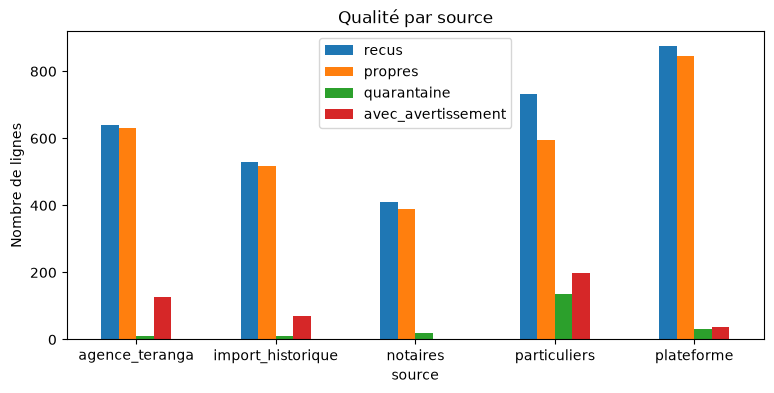

In [72]:
# Tableau : une ligne par source, avec le nom de la source comme index
par_source = pd.DataFrame(rapport["par_source"])
par_source = par_source.set_index("source")
par_source = par_source.apply(pd.to_numeric, errors="coerce")

# Graphique : une couleur par indicateur, une barre par source
par_source[["recus", "propres", "quarantaine", "avec_avertissement"]].plot(kind="bar", figsize=(9, 4))
plt.title("Qualité par source")
plt.ylabel("Nombre de lignes")
plt.xticks(rotation=0)
plt.show()